# 긴 글을 나누어 다음 문자 예측하기

**본인 사본을 만들어 실행·수정·기록하세요.**

- 이름: **⟦이윤호⟧**
- 학번: **⟦2022204025⟧**

[자습 자료](https://nii-lab.github.io/ko/courses/ai-applications/lstm-gru/index.html)

<!-- exercise-guidance:ai-applications/lstm-gru/execution -->
- Code Cell 실행: ▶ 또는 `Shift+Enter`, 위에서부터 순서대로.
- Text Cell 작성: 더블클릭 → `직접 입력` 작성 → `Shift+Enter`.
- 직접 작성 셀: 본인 코드 입력.
- 값 변경 후: 해당 셀과 뒤의 관련 셀 다시 실행.
<!-- /exercise-guidance:ai-applications/lstm-gru/execution -->


## 1. 긴 글에서 짧은 학습 예제 만들기

`hello!`를 `h → e → l → l → o → !`처럼 순서대로 읽어 보세요. 이렇게 순서가 있는 나열이 **Sequence**입니다. 문자 하나가 한 시점이며 공백도 한 문자입니다.

원문에서 일정한 길이로 잘라 보는 구간을 **Window**라고 합니다. 길이 3으로 `hel`을 읽을 때 각 위치의 다음 문자 정답은 `ell`입니다. `h` 다음은 `e`, `he` 다음은 `l`, `hel` 다음은 `l`입니다. 정답은 마지막 하나만이 아니라 각 위치마다 있습니다.

| 예제 | 원문 시작 위치 | Input | Target |
|---|---:|---|---|
| 1 | 0 | `hel` | `ell` |
| 2 | 2 | `llo` | `lo!` |

**Window Size=3**은 입력 길이, **Stride=2**는 다음 예제의 시작점을 옮기는 간격입니다. Target은 언제나 Input보다 **한 글자 뒤**입니다. Stride가 2여도 두 글자 뒤를 예측하지 않습니다. 예제 1과 2는 원문 위치 2를 함께 포함합니다.

두 예제를 행으로 쌓으면 Batch가 됩니다. 행 수 N=2, 행 안의 문자 수 S=3이며, 문자마다 길이 E의 One-hot 벡터를 넣으면 Input shape는 `(2,3,E)`입니다. 한 행 안에서 State는 다음 문자로 전달되지만, 다른 행으로 넘기지는 않습니다.

### A-1. 짧은 문자열로 자르는 규칙 확인하기


In [1]:
# 한 예제의 입력 길이와 다음 예제로 이동하는 간격을 구별하세요.
demo_text = "hello!"
demo_size, demo_stride = 3, 2
for start in range(0, len(demo_text) - demo_size, demo_stride):
    inp = demo_text[start:start + demo_size]
    target = demo_text[start + 1:start + demo_size + 1]
    print(f"시작 위치 {start}: Input={inp!r}, Target={target!r}")


시작 위치 0: Input='hel', Target='ell'
시작 위치 2: Input='llo', Target='lo!'


### A-2. 긴 글에 같은 규칙 적용하기

이제 입력 길이를 20, 이동 간격을 5로 정합니다. 시작 위치는 0·5·10·…이며, 각 Target은 Input보다 한 글자 뒤에서 시작합니다. 마지막 정답까지 있으려면 입력 길이보다 한 글자 더 필요합니다. 만든 예제를 모두 한 Batch로 묶으며, 실제 N·S·E는 출력으로 확인하세요.


In [2]:
import sys, numpy as np, matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
torch.manual_seed(42)
torch.set_num_threads(2)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)
sentences=["if you want to build a ship, don't drum up people together to", "collect wood and don't assign them tasks and work, but rather", "teach them to long for the endless immensity of the sea."]
sentence=' '.join(sentences);chars=sorted(set(sentence));vocab={c:i for i,c in enumerate(chars)}
window_size = 20
window_stride = 5
starts = range(0, len(sentence) - window_size, window_stride)
ids = torch.tensor([[vocab[c] for c in sentence[i:i+window_size]] for i in starts])
Y = torch.tensor([[vocab[c] for c in sentence[i+1:i+window_size+1]] for i in starts])
X = F.one_hot(ids, num_classes=len(chars)).float()
print('X:', X.shape, 'Y:', Y.shape)
for i in range(2):
    print('input:', ''.join(chars[j] for j in ids[i]))
    print('target:', ''.join(chars[j] for j in Y[i]))
assert X.shape[:2] == Y.shape


Python: 3.12.3 | PyTorch: 2.12.0+cu130
X: torch.Size([32, 20, 25]) Y: torch.Size([32, 20])
input: if you want to build
target: f you want to build 
input: u want to build a sh
target:  want to build a shi


### B. 직접 수행

<!-- exercise-guidance:ai-applications/lstm-gru/activity-1 -->
1. 첫 예제 셀에서 `hello!`를 길이 3·Stride 2로 자른 두 Input·Target 쌍을 출력하세요. 각 쌍의 Input과 Target을 위아래 두 행으로 놓고 같은 열에서 한 글자 차이가 나는지 대조하세요.
2. 긴 글을 처리하는 데이터 셀의 첫 두 Input·Target 쌍에도 같은 표시를 하세요. 두 예제의 시작 위치가 몇 글자씩 이동하는지 적으세요.
3. `X.shape`와 `Y.shape`의 각 축에 Window 수 $N$, 길이 $S$, 문자 표현 크기 $E$를 대응시키세요.
<!-- /exercise-guidance:ai-applications/lstm-gru/activity-1 -->

예상은 정확한 수치 대신 shape나 증가·감소 방향으로 적어도 됩니다. 설명은 아래 Text Cell에 기록하세요.


In [3]:
for start in range(0, len(demo_text) - demo_size, demo_stride):
    inp = demo_text[start:start + demo_size]
    target = demo_text[start + 1:start + demo_size + 1]
    print(f'시작 위치 {start}')
    print('Input :', ' '.join(inp))
    print('Target:', ' '.join(target))

print('\n긴 글의 첫 두 Window를 문자별로 대조')
for i in range(2):
    input_text = ''.join(chars[j] for j in ids[i].tolist())
    target_text = ''.join(chars[j] for j in Y[i].tolist())
    print(f'시작 위치 {i * window_stride}')
    print('Input :', ' '.join(input_text))
    print('Target:', ' '.join(target_text))
print('\n전체 글자 수:', len(sentence))
print('Vocabulary 크기 E:', len(chars))
print('X.shape (Window 수 N, 길이 S, One-hot 크기 E):', tuple(X.shape))
print('Y.shape (Window 수 N, 길이 S):', tuple(Y.shape))
print('시작 위치 간격:', window_stride)


시작 위치 0
Input : h e l
Target: e l l
시작 위치 2
Input : l l o
Target: l o !

긴 글의 첫 두 Window를 문자별로 대조
시작 위치 0
Input : i f   y o u   w a n t   t o   b u i l d
Target: f   y o u   w a n t   t o   b u i l d  
시작 위치 5
Input : u   w a n t   t o   b u i l d   a   s h
Target:   w a n t   t o   b u i l d   a   s h i

전체 글자 수: 180
Vocabulary 크기 E: 25
X.shape (Window 수 N, 길이 S, One-hot 크기 E): (32, 20, 25)
Y.shape (Window 수 N, 길이 S): (32, 20)
시작 위치 간격: 5


### C. 직접 기록 · 이 Text Cell을 더블클릭해서 수정

- 확인하거나 바꾼 조건: `hello!`는 Window Size 3·Stride 2, 긴 글은 Window Size 20·Stride 5로 나누었습니다.
- 실행 전 예상: 긴 글의 `X.shape = (Window 수, 20, Vocabulary 크기)`, `Y.shape = (Window 수, 20)`이 될 것으로 예상했습니다.
- 실제 출력/그래프에서 확인한 값: `hello!`는 `hel → ell`, `llo → lo!`로 나왔습니다. 긴 글은 180자, Vocabulary는 25개였고 Window는 32개였습니다. 따라서 `X.shape`는 `(32,20,25)`, `Y.shape`는 `(32,20)`이었습니다. 긴 글의 첫 두 Window 시작 위치는 0과 5였습니다.
- 예상과 차이 및 설명: 예상한 shape과 같았습니다.

## 2. RNN·LSTM·GRU 비교

같은 Window 데이터와 학습 조건으로 RNN·LSTM·GRU를 비교합니다. 각 모델은 Hidden Size=32이며, 모든 시점의 output을 Linear에 넣어 문자 점수를 만듭니다. LSTM만 Hidden State 외에 Cell State를 반환합니다. 학습 결과는 results에 저장되므로 표와 State 확인을 위해 다시 학습할 필요는 없습니다.

### A. 기준 예제 · 먼저 읽고 실행


RNN 0 3.2361576557159424
RNN 100 0.14867515861988068
RNN 200 0.05875656008720398
RNN accuracy: 0.973437488079071
p you want to build 
LSTM 0 3.270946979522705
LSTM 100 0.4285316467285156
LSTM 200 0.07596205174922943
LSTM accuracy: 0.973437488079071
p you want to build 
GRU 0 3.213665008544922
GRU 100 0.11304806172847748
GRU 200 0.049983810633420944
GRU accuracy: 0.973437488079071
p you want to build 


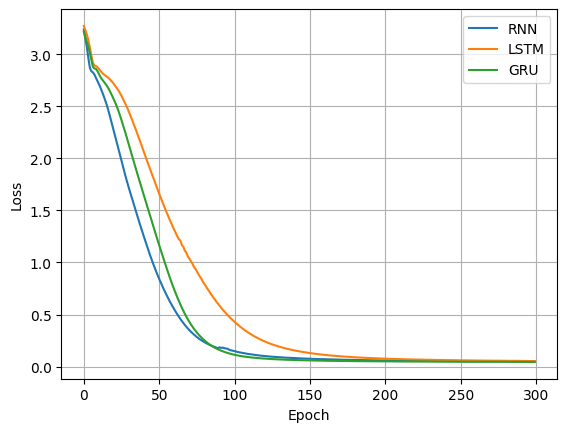

LSTM output: torch.Size([32, 20, 32]) h_n: torch.Size([1, 32, 32]) c_n: torch.Size([1, 32, 32])
RNN output: torch.Size([32, 20, 32]) h_n: torch.Size([1, 32, 32])
GRU output: torch.Size([32, 20, 32]) h_n: torch.Size([1, 32, 32])


In [4]:
class CharModel(nn.Module):
    def __init__(self,kind,vocab_size,hidden=32):
        super().__init__();self.rnn=getattr(nn,kind)(vocab_size,hidden,batch_first=True);self.fc=nn.Linear(hidden,vocab_size)
    def forward(self,x):
        output,state=self.rnn(x);return self.fc(output)
def fit_char(kind,X,Y,epochs=300,lr=.01):
    torch.manual_seed(42);m=CharModel(kind,X.shape[-1]);opt=torch.optim.Adam(m.parameters(),lr=lr);losses=[]
    for epoch in range(epochs):
        logits=m(X);loss=F.cross_entropy(logits.reshape(-1,X.shape[-1]),Y.reshape(-1))
        opt.zero_grad();loss.backward();opt.step();losses.append(loss.item())
        if epoch%100==0:print(kind,epoch,loss.item())
    with torch.no_grad():pred=m(X).argmax(-1)
    return m,losses,pred
results={}
for kind in ['RNN','LSTM','GRU']:
    m,h,p=fit_char(kind,X,Y,epochs=300,lr=.01);results[kind]=(m,h,p)
    print(kind,'accuracy:',(p==Y).float().mean().item());print(''.join(chars[i] for i in p[0]))
    plt.plot(h,label=kind)
plt.legend();plt.xlabel('Epoch');plt.ylabel('Loss');plt.grid();plt.show()
with torch.no_grad():output,(h_n,c_n)=results['LSTM'][0].rnn(X)
print('LSTM output:',output.shape,'h_n:',h_n.shape,'c_n:',c_n.shape)
for kind in ['RNN', 'GRU']:
    with torch.no_grad(): output, h_n = results[kind][0].rnn(X)
    print(kind, 'output:', output.shape, 'h_n:', h_n.shape)



### B. 직접 수행

<!-- exercise-guidance:ai-applications/lstm-gru/activity-2 -->
1. 모델 학습 셀을 실행하세요. RNN·LSTM·GRU별 마지막 Loss·Training Accuracy·첫 Window의 예측 문자열을 한 표로 적으세요. 사용한 데이터·epoch·Learning Rate는 세 모델에서 동일하게 둡니다.
2. State 출력 셀을 실행하고, 모델별 `output`·`h_n`·`c_n`의 shape를 표로 적으세요. 반환하지 않는 State는 ‘없음’으로 표시하세요.
3. `output`의 Sequence 축과 `h_n`의 마지막 시점 표현을 구분해 설명하고, LSTM이 추가로 반환하는 `c_n`의 역할을 적으세요.
<!-- /exercise-guidance:ai-applications/lstm-gru/activity-2 -->

예상은 정확한 수치 대신 shape나 증가·감소 방향으로 적어도 됩니다. 설명은 아래 Text Cell에 기록하세요.


In [ ]:
print('모델별 학습 결과')
for kind, (trained_model, losses, predictions) in results.items():
    accuracy = (predictions == Y).float().mean().item()
    first_prediction = ''.join(chars[i] for i in predictions[0].tolist())
    first_target = ''.join(chars[i] for i in Y[0].tolist())
    print(f'{kind}: final loss={losses[-1]:.6f}, training accuracy={accuracy:.4f}')
    print(f'  첫 Window target:     {first_target!r}')
    print(f'  첫 Window prediction: {first_prediction!r}')
    with torch.no_grad():
        output, state = trained_model.rnn(X)
    if kind == 'LSTM':
        h_n, c_n = state
        print(f'  output={tuple(output.shape)}, h_n={tuple(h_n.shape)}, c_n={tuple(c_n.shape)}')
    else:
        h_n = state
        print(f'  output={tuple(output.shape)}, h_n={tuple(h_n.shape)}, c_n=없음')


모델별 학습 결과 (데이터와 설정은 동일: epochs=300, lr=0.01)
RNN: final loss=0.048671, training accuracy=0.9734
  첫 Window target:     'f you want to build '
  첫 Window prediction: 'p you want to build '
  output=(32, 20, 32), h_n=(1, 32, 32), c_n=없음
LSTM: final loss=0.053359, training accuracy=0.9734
  첫 Window target:     'f you want to build '
  첫 Window prediction: 'p you want to build '
  output=(32, 20, 32), h_n=(1, 32, 32), c_n=(1, 32, 32)
GRU: final loss=0.044863, training accuracy=0.9734
  첫 Window target:     'f you want to build '
  첫 Window prediction: 'p you want to build '
  output=(32, 20, 32), h_n=(1, 32, 32), c_n=없음


### C. 직접 기록 · 이 Text Cell을 더블클릭해서 수정

- 확인하거나 바꾼 조건: RNN·LSTM·GRU를 같은 데이터로 Hidden Size 32, Epoch 300, Learning Rate 0.01로 학습했습니다.
- 실행 전 예상: `output`은 `(32,20,32)`, `h_n`은 `(1,32,32)`이고 LSTM에만 `c_n`이 추가될 것으로 예상했습니다.
- 실제 출력/그래프에서 확인한 값: Training Accuracy는 세 모델 모두 0.9734였습니다. 마지막 Loss는 RNN 0.048671, LSTM 0.053359, GRU 0.044863이었습니다. 첫 Window 예측은 세 모델 모두 `p you want to build `이었습니다.
- 예상과 차이 및 설명: State shape은 예상과 같았습니다. GRU의 Loss가 가장 낮았지만 이번 데이터와 설정에서의 결과로만 비교했습니다.


## 반복 숙달 · 실행 전에 판단하기

앞서 비교한 RNN·LSTM·GRU의 결과를 이 표에 정리했습니다. 같은 데이터·Epoch·Learning Rate로 학습한 결과입니다.

| 변경 조건 | 예상 shape/수치/결과 | 실제 결과 | 오류가 있었다면 원인 |
|---|---|---|---|
| RNN | `output (32,20,32)`, `h_n (1,32,32)`, `c_n` 없음 | Loss 0.048671, 정확도 0.9734, 첫 예측 `p you want to build ` | - |
| LSTM | `output (32,20,32)`, `h_n`·`c_n` 모두 `(1,32,32)` | Loss 0.053359, 정확도 0.9734, 첫 예측 `p you want to build ` | - |
| GRU | `output (32,20,32)`, `h_n (1,32,32)`, `c_n` 없음 | Loss 0.044863, 정확도 0.9734, 첫 예측 `p you want to build ` | - |


In [ ]:
# ✍ 반복 실험 코드
for kind, (trained_model, _, _) in results.items():
    with torch.no_grad():
        short_input = X[:, :10, :]
        short_output = trained_model(short_input)
    print(f'{kind}: 입력 {tuple(short_input.shape)} → 출력 {tuple(short_output.shape)}')

with torch.no_grad():
    debug_logits = results['LSTM'][0](X)
flat_logits = debug_logits.reshape(-1, debug_logits.shape[-1])
flat_target = Y.reshape(-1)
print('Logits:', tuple(debug_logits.shape), '→', tuple(flat_logits.shape))
print('Target:', tuple(flat_target.shape))
print('Loss:', F.cross_entropy(flat_logits, flat_target).item())


## 선택 실습 · 오류의 원인을 찾아 코드 고치기

<!-- exercise-guidance:ai-applications/lstm-gru/optional -->
**문자별 Logits와 Target을 펼치는 축이 맞지 않는 경우**

1. LSTM 학습까지 마친 뒤, 노트북 맨 아래에 Code Cell을 추가하고 다음 코드를 실행하세요.
   
   ```python
   with torch.no_grad():
       debug_logits = results['LSTM'][0](X)
   debug_flat_logits = debug_logits.reshape(-1, debug_logits.shape[-1])
   print("Logits:", debug_logits.shape, "flattened:", debug_flat_logits.shape)
   for debug_target in [Y, Y.reshape(-1)]:
       print("Target:", debug_target.shape)
       try:
           print("Loss:", F.cross_entropy(debug_flat_logits, debug_target).item())
       except (RuntimeError, ValueError) as error:
           print(type(error).__name__, str(error))
   ```
2. Text Cell에 두 Target shape와 실행 성공 여부를 표로 적으세요. 펼친 Logits의 한 행이 무엇을 예측하며, 그 행에 대응하는 Target을 어느 축 순서로 나열해야 하는지 설명하세요.
<!-- /exercise-guidance:ai-applications/lstm-gru/optional -->

## 저장 전 확인

1. 작성란과 출력·그래프를 확인하고 새 런타임에서 전체 셀을 순서대로 실행하세요.
2. 본인 Drive에 저장한 뒤 `.ipynb`로 내려받으세요.

<!-- exercise-guidance:ai-applications/lstm-gru/submission -->
코드, 실제 Output·그래프, 직접 작성한 해석을 포함하세요.  제출은 KLAS를 이용하며 기한은 학기 일정과 최신 공지를 확인합니다.

파일명: `이름_학번_13주차.ipynb`.
<!-- /exercise-guidance:ai-applications/lstm-gru/submission -->


In [ ]:
with torch.no_grad():
    debug_logits = results['LSTM'][0](X)
debug_flat_logits = debug_logits.reshape(-1, debug_logits.shape[-1])
print("Logits:", tuple(debug_logits.shape), "flattened:", tuple(debug_flat_logits.shape))
for debug_target in [Y, Y.reshape(-1)]:
    print("Target:", tuple(debug_target.shape))
    try:
        print("Loss:", F.cross_entropy(debug_flat_logits, debug_target).item())
    except (RuntimeError, ValueError) as error:
        print(type(error).__name__, str(error))


* Logits `(32,20,25)`는 Window 32개, 각 Window의 20개 위치, Vocabulary 25개 점수로 읽었습니다. Cross Entropy에 넣기 위해 앞의 두 축을 합치면 `(640,25)`가 되고, Target도 같은 순서로 펼쳐 `(640,)`으로 맞춰야 합니다. 또한, `Y`를 `(32,20)` 그대로 넣었을 때는 Logits의 행 수 640과 Target 항목 수 32가 맞지 않아 오류가 발생하였습니다.